# Task 4 Semi-supervised learning for unlabeled data

## Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer
from catboost import CatBoostRegressor
from sklearn.manifold import Isomap
from sklearn.decomposition import PCA
from sklearn.base import BaseEstimator

## Auxiliary functions

In [2]:
def cMSE(y, y_hat, c):
    err = y-y_hat
    err = (1-c)*err**2 + c*np.maximum(0,err)**2
    return np.sum(err)/err.shape[0]
    
def plot_y_yhat(y_test, y_pred, plot_title="plot"):
    label = 'SurvivalTime'
    MAX = 500

    if len(y_test) > MAX:
        idx = np.random.choice(len(y_test), MAX, replace=False)
    else:
        idx = np.arange(len(y_test))

    plt.figure(figsize=(6, 6))
    x0 = np.min(y_test[idx])
    x1 = np.max(y_test[idx])
    plt.scatter(y_test[idx], y_pred[idx], alpha=0.7)
    plt.xlabel(f'True {label}')
    plt.ylabel(f'Predicted {label}')
    plt.plot([x0, x1], [x0, x1], color='red')
    plt.title(f'True vs Predicted {label}')
    plt.axis('square')
    plt.savefig(plot_title + '.pdf')
    plt.show()
    
def save_predictions(predictions, path):
    df = pd.DataFrame({
        'id': range(len(predictions)),
        '0': predictions
    })
    
    df.to_csv(path, index=False)
    
def model_metrics(y_true, y_pred):
    error = y_true - y_pred
    metrics = {
        'Max Error': np.max(np.abs(error)),
        'Min Error': np.min(np.abs(error)),
        'Mean Error': np.mean(np.abs(error)),
        'Standard Deviation': np.std(error)
    }
    return metrics
    
def evaluate_model(X, y, c, model, show_cmse=True, show_plot=False):
    X_train, X_test, y_train, y_test, c_train, c_test = train_test_split(X, y, c, test_size=0.2, random_state=30)
    
    y_pred_cv = cross_val_predict(model, X_train, y_train, cv=10)
    cMSE_cv = cMSE(y_train, y_pred_cv, c_train)
    
    model.fit(X_train, y_train)
    
    y_pred = model.predict(X_test)
    cMSE_test = cMSE(y_test, y_pred, c_test)
    
    if show_cmse:
        print(f"CV cMSE: {cMSE_cv}")
        print(f"Test cMSE: {cMSE_test}")
    
    if show_plot:
        plot_y_yhat(y_test, y_pred, plot_title="y_yhat_plot")
    
    return model, cMSE_cv, cMSE_test, model_metrics(y_test, y_pred)

## Data processing

In [3]:
df = pd.read_csv('./mlNOVA/train_data.csv')
df.drop(columns=['id'], inplace=True)

labeled_df = df.dropna(subset=['SurvivalTime'])
unlabeled_df = df[df['SurvivalTime'].isna()]

X_labeled = labeled_df.drop(columns=['SurvivalTime', 'Censored'])
y_labeled = labeled_df['SurvivalTime']
c_labeled = labeled_df['Censored']

X_unlabeled = unlabeled_df.drop(columns=['SurvivalTime', 'Censored'])
c_unlabeled = unlabeled_df['Censored']

X = pd.concat([X_labeled, X_unlabeled])
c = pd.concat([c_labeled, c_unlabeled])

## Task 4.1: Imputation with labeled and unlabeled data

### Fit with the best imputation methods from Task 3.1

#### Best imputer from task 3.1 was KNN imputer with K=19

In [4]:
knn_imputer = KNNImputer(n_neighbors=19)
X_imp = pd.DataFrame(knn_imputer.fit_transform(X), columns=X.columns)
X_labeled_imp = X_imp.iloc[:len(labeled_df)]

#### Use the imputed data with labels to train a Linear Regression model

In [20]:
linear_reg = make_pipeline(StandardScaler(), LinearRegression())
_, _, _, _ = evaluate_model(np.array(X_labeled_imp), np.array(
    y_labeled), np.array(c_labeled), model=linear_reg)

CV cMSE: 2.606016778008581
Test cMSE: 2.418972175074191


### Training an Isomap lower dimensional representation of the data

#### Required wrapper code

In [8]:
class FrozenTransformer(BaseEstimator):
    def __init__(self, fitted_transformer):
        self.fitted_transformer = fitted_transformer

    def __getattr__(self, name):
        # `fitted_transformer`'s attributes are now accessible
        return getattr(self.fitted_transformer, name)

    def __sklearn_clone__(self):
        return self

    def fit(self, X, y=None):
        # Fitting does not change the state of the estimator
        return self

    def transform(self, X, y=None):
        # transform only transforms the data
        return self.fitted_transformer.transform(X)

    def fit_transform(self, X, y=None):
        # fit_transform only transforms the data
        return self.fitted_transformer.transform(X)

#### Standardize the features

In [9]:
scaler = StandardScaler()
X_imp_scaled = scaler.fit_transform(X_imp)

#### Without PCA, find out best n_components for Isomap

##### Plot performance of different number of components on Isomap

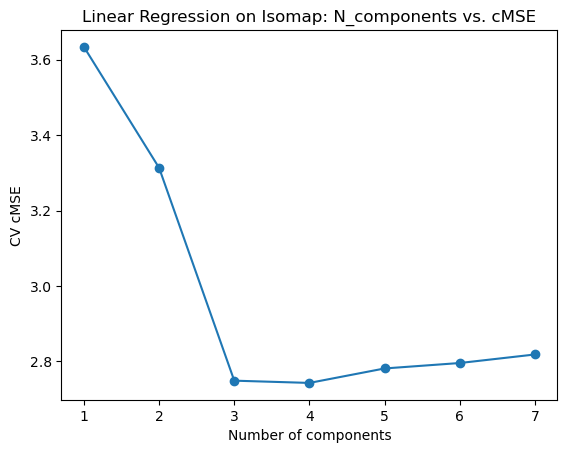

In [10]:
n_values = range(1, 8)
ft_lr_scores = []

for n in n_values:
    iso = Isomap(n_components=n)
    iso.fit(X_imp_scaled)

    ft_lr_model = make_pipeline(
        knn_imputer,
        scaler,
        FrozenTransformer(iso),
        LinearRegression())

    _, score, _, _ = evaluate_model(np.array(
        X_labeled_imp), np.array(y_labeled), np.array(c_labeled), model=ft_lr_model, show_cmse=False)

    ft_lr_scores.append(score)

plt.plot(n_values, ft_lr_scores, marker='o')
plt.xlabel("Number of components")
plt.ylabel("CV cMSE")
plt.title("Linear Regression on Isomap: N_components vs. cMSE")
plt.show()

##### Best number of components is 4

In [13]:
iso = Isomap(n_components=4)
iso.fit(X_imp_scaled)

ft_lr_model = make_pipeline(
    knn_imputer, 
    scaler,
    FrozenTransformer(iso), 
    LinearRegression())

ft_lr_imp_model, ft_lr_imp_csme, _, _ = evaluate_model(np.array(
    X_labeled_imp), np.array(y_labeled), np.array(c_labeled), model=ft_lr_model)

CV cMSE: 2.743067094031062
Test cMSE: 2.790788187401173


#### For best Isomap (4 components), find out best n_components for PCA 

PCA does NOT help in this case

##### Plot performance of different component numbers on PCA

c:\Users\rasvi\anaconda3\envs\ml\Lib\site-packages\sklearn\manifold\_isomap.py:359: UserWarning: The number of connected components of the neighbors graph is 6 > 1. Completing the graph to fit Isomap might be slow. Increase the number of neighbors to avoid this issue.
  self._fit_transform(X)
c:\Users\rasvi\anaconda3\envs\ml\Lib\site-packages\scipy\sparse\_index.py:108: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_intXint(row, col, x.flat[0])
c:\Users\rasvi\anaconda3\envs\ml\Lib\site-packages\scipy\sparse\_index.py:108: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_intXint(row, col, x.flat[0])
c:\Users\rasvi\anaconda3\envs\ml\Lib\site-packages\scipy\sparse\_index.py:108: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_intXint(row, col, x.flat

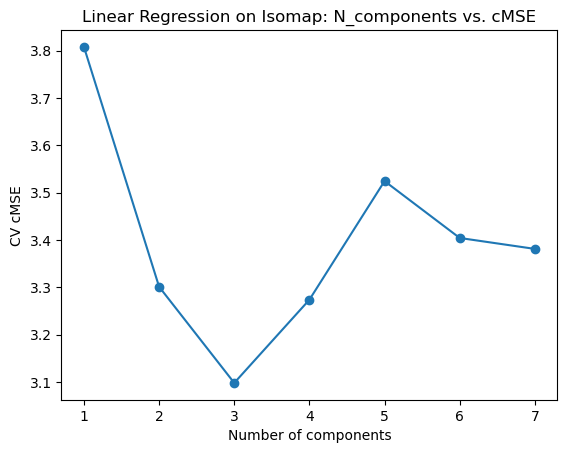

In [12]:
n_values = range(1, 8)
ft_lr_scores = []

for n in n_values:
    pca = PCA(n_components=n)
    X_pca = pca.fit_transform(X_imp_scaled)

    iso = Isomap(n_components=4)
    iso.fit(X_pca)

    ft_lr_model = make_pipeline(
        knn_imputer,
        scaler,
        pca,
        FrozenTransformer(iso),
        LinearRegression())

    _, score, _, _ = evaluate_model(np.array(
        X_labeled_imp), np.array(y_labeled), np.array(c_labeled), model=ft_lr_model, show_cmse=False)

    ft_lr_scores.append(score)

plt.plot(n_values, ft_lr_scores, marker='o')
plt.xlabel("Number of components")
plt.ylabel("CV cMSE")
plt.title("Linear Regression on Isomap: N_components vs. cMSE")
plt.show()

##### Best number of components is 3

In [13]:
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_imp_scaled)

iso = Isomap(n_components=4)
iso.fit(X_pca)

ft_lr_pca_model = make_pipeline(
    knn_imputer,
    scaler,
    pca,
    FrozenTransformer(iso),
    LinearRegression())

_, _, _, _ = evaluate_model(np.array(
    X_labeled_imp), np.array(y_labeled), np.array(c_labeled), model=ft_lr_pca_model)

CV cMSE: 3.098207207441531
Test cMSE: 2.5444805696691994


## Task 4.2 Evaluation

### Compare the results of the strategies developed in Task 4.1  with the baseline model in the slides, using a table with the error statistics and the y-y hat plot.

In [14]:
knn_imputer = KNNImputer(n_neighbors=19)
X_imp = pd.DataFrame(knn_imputer.fit_transform(X), columns=X.columns)
X_labeled_imp = X_imp.iloc[:len(labeled_df)]

iso = Isomap(n_components=4)
iso.fit(X_imp_scaled)

ft_lr_model = make_pipeline(
    knn_imputer, 
    scaler,
    FrozenTransformer(iso), 
    LinearRegression())

_, _, _, lr_metrics = evaluate_model(np.array(
    X_labeled_imp), np.array(y_labeled), np.array(c_labeled), model=ft_lr_model)

CV cMSE: 2.7430670940310615
Test cMSE: 2.790788187401173


### Try the best imputation strategies of Task 3.1, impute the data, run the best model of task 3.2 and compare with the baseline in the slides.

##### KNN imputer with K=19

In [15]:
knn_imputer = KNNImputer(n_neighbors=19)
X_imp = pd.DataFrame(knn_imputer.fit_transform(X), columns=X.columns)
X_labeled_imp = X_imp.iloc[:len(labeled_df)]

##### Train best model from task 3.2 (CatBoost with learning rate=0.01 and max_depth=1)

In [16]:
scaler = StandardScaler()
X_imp_scaled = scaler.fit_transform(X_imp)

iso = Isomap(n_components=3)
iso.fit(X_imp_scaled)

model = CatBoostRegressor(random_state=30, max_depth=1, learning_rate=0.01, silent=True)

ft_cat_model = make_pipeline(
    knn_imputer,
    scaler,
    FrozenTransformer(iso), 
    model)

_, ft_cat_imp_model, _, cat_metrics = evaluate_model(np.array(
    X_labeled_imp), np.array(y_labeled), np.array(c_labeled), model=ft_cat_model)

CV cMSE: 2.591613815083378
Test cMSE: 2.6944631966777703


##### Find best value for n_components

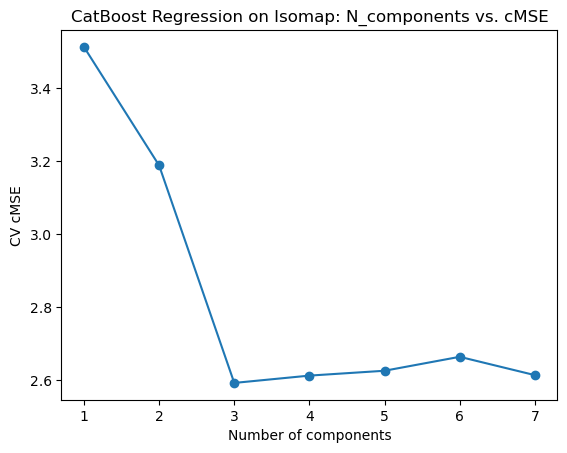

In [23]:
n_values = range(1, 8)
ft_cat_scores = []

for n in n_values:
    iso = Isomap(n_components=n)
    iso.fit(X_imp_scaled)

    model = CatBoostRegressor(random_state=30, max_depth=1, learning_rate=0.01, silent=True)

    ft_cat_model = make_pipeline(
        knn_imputer,
        scaler,
        FrozenTransformer(iso),
        model)

    _, score, _, _ = evaluate_model(np.array(
        X_labeled_imp), np.array(y_labeled), np.array(c_labeled), model=ft_cat_model, show_cmse=False)

    ft_cat_scores.append(score)

plt.plot(n_values, ft_cat_scores, marker='o')
plt.xlabel("Number of components")
plt.ylabel("CV cMSE")
plt.title("CatBoost Regression on Isomap: N_components vs. cMSE")
plt.show()

##### PCA

c:\Users\rasvi\anaconda3\envs\ml\Lib\site-packages\sklearn\manifold\_isomap.py:359: UserWarning: The number of connected components of the neighbors graph is 6 > 1. Completing the graph to fit Isomap might be slow. Increase the number of neighbors to avoid this issue.
  self._fit_transform(X)
c:\Users\rasvi\anaconda3\envs\ml\Lib\site-packages\scipy\sparse\_index.py:108: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_intXint(row, col, x.flat[0])
c:\Users\rasvi\anaconda3\envs\ml\Lib\site-packages\scipy\sparse\_index.py:108: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_intXint(row, col, x.flat[0])
c:\Users\rasvi\anaconda3\envs\ml\Lib\site-packages\scipy\sparse\_index.py:108: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_intXint(row, col, x.flat

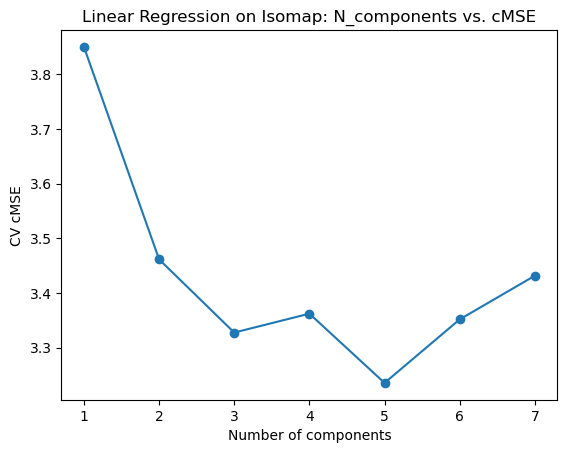

In [ ]:
n_values = range(1, 8)
ft_cat_scores = []

for n in n_values:
    pca = PCA(n_components=n)
    X_pca = pca.fit_transform(X_imp_scaled)

    iso = Isomap(n_components=3)
    iso.fit(X_pca)

    model = CatBoostRegressor(
        random_state=30, max_depth=1, learning_rate=0.01, silent=True)

    ft_cat_model = make_pipeline(
        knn_imputer,
        scaler,
        pca,
        FrozenTransformer(iso),
        model
    )

    _, score, _, _ = evaluate_model(np.array(
        X_labeled_imp), np.array(y_labeled), np.array(c_labeled), model=ft_cat_model, show_cmse=False)

    ft_cat_scores.append(score)

plt.plot(n_values, ft_cat_scores, marker='o')
plt.xlabel("Number of components")
plt.ylabel("CV cMSE")
plt.title("Linear Regression on Isomap: N_components vs. cMSE")
plt.show()

In [ ]:
pca = PCA(n_components=5)
X_pca = pca.fit_transform(X_imp_scaled)

iso = Isomap(n_components=3)
iso.fit(X_pca)

model = CatBoostRegressor(
        random_state=30, max_depth=1, learning_rate=0.01, silent=True)


ft_cat_pca_model = make_pipeline(
    knn_imputer, 
    scaler, 
    pca,
    FrozenTransformer(iso), 
    model)

_, _, _, _= evaluate_model(np.array(
    X_labeled_imp), np.array(y_labeled), np.array(c_labeled), model=ft_cat_pca_model)

c:\Users\rasvi\anaconda3\envs\ml\Lib\site-packages\sklearn\manifold\_isomap.py:359: UserWarning: The number of connected components of the neighbors graph is 2 > 1. Completing the graph to fit Isomap might be slow. Increase the number of neighbors to avoid this issue.
  self._fit_transform(X)
c:\Users\rasvi\anaconda3\envs\ml\Lib\site-packages\scipy\sparse\_index.py:108: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_intXint(row, col, x.flat[0])


CV cMSE: 3.235286862633284
Test cMSE: 2.897578264648125


##### Metrics for linear regression and CatBoost

In [17]:
table = pd.DataFrame({
    'Linear regression': lr_metrics,
    'CatBoost': cat_metrics,
})

table.T.head()

,Max Error,Min Error,Mean Error,Standard Deviation
Linear regression,6.570791,0.018893,1.320010,1.794507
CatBoost,6.290252,0.032914,1.282456,1.778130


### Submission

In [ ]:
X_kaggle_df = pd.read_csv('./mlNOVA/test_data.csv')
X_kaggle_df.drop(columns=['id'], inplace=True)

imputer_knn = KNNImputer(n_neighbors=19)
X_imp_knn = imputer_knn.fit_transform(X_kaggle_df)

CV cMSE: 2.591613815083378
Test cMSE: 2.6944631966777703


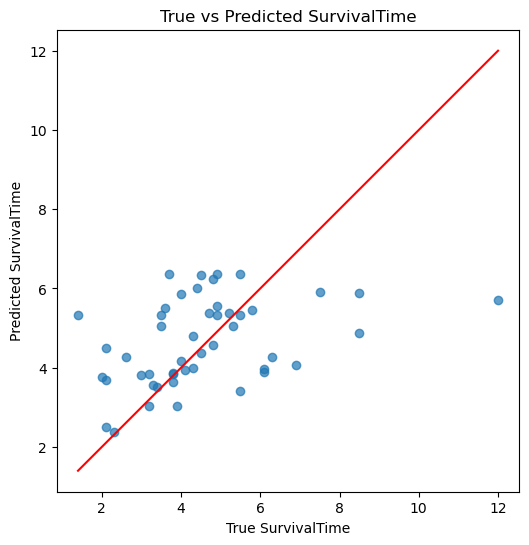

In [18]:
_, ft_cat_imp_model, _, _ = evaluate_model(np.array(
    X_labeled_imp), np.array(y_labeled), np.array(c_labeled), model=ft_cat_model, show_plot=True)

In [146]:
y_cat_imp_knn_pred = ft_cat_imp_model.predict(X_imp_knn)
save_predictions(y_cat_imp_knn_pred, './submissions/semisupervised-submission-01.csv')